In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
     

X,y = make_classification(n_features=5, n_redundant=0, n_informative=5,n_clusters_per_class=1)
     

df = pd.DataFrame(X,columns=['col1','col2','col3','col4','col5'])
df['target'] = y
print(df.shape)
df.head()
     

(100, 6)


,col1,col2,col3,col4,col5,target
0,-1.647490,1.530277,-1.113886,2.113682,-2.695281,0
1,-1.890058,-1.083646,-0.307917,0.413432,-0.568047,1
2,0.151560,1.513574,2.181150,0.697881,-0.916667,1
3,-1.196551,1.528621,0.494806,0.177234,0.385606,1
4,-0.325597,1.566038,-1.341782,-0.538514,-2.248741,0


In [2]:
# function for row sampling

def sample_rows(df,percent):
  return df.sample(int(percent*df.shape[0]),replace=True)
     

In [6]:
import random


# function for feature sampling
def sample_features(df,percent):
  cols = random.sample(df.columns.tolist()[:-1],int(percent*(df.shape[1]-1)))
  new_df = df[cols]
  new_df['target'] = df['target']
  return new_df
     

In [7]:
# function for combined sampling

def combined_sampling(df,row_percent,col_percent):
  new_df = sample_rows(df,row_percent)
  return sample_features(new_df,col_percent)
     

In [8]:
df1 = combined_sampling(df,0.5,0.5)

/var/folders/y2/sdgjnlgd3znfjymq07bh0d_00000gn/T/ipykernel_30144/693359978.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


In [9]:
df2 = combined_sampling(df,0.5,0.5)

/var/folders/y2/sdgjnlgd3znfjymq07bh0d_00000gn/T/ipykernel_30144/693359978.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


In [10]:
df3 = combined_sampling(df,0.5,0.5)


/var/folders/y2/sdgjnlgd3znfjymq07bh0d_00000gn/T/ipykernel_30144/693359978.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']


In [11]:
print(df1.columns)
print(df2.columns)
print(df3.columns)

Index(['col4', 'col5', 'target'], dtype='object')
Index(['col1', 'col2', 'target'], dtype='object')
Index(['col1', 'col5', 'target'], dtype='object')


In [12]:

df3

,col1,col5,target
77,1.115406,-0.753542,0
23,-1.251945,0.564838,1
39,-2.124010,-1.148440,1
72,-0.047212,0.905241,1
54,0.586988,-1.383258,0
22,-0.781098,-2.319516,1
89,-0.477308,-1.291326,1
79,-0.991700,-2.116294,1
56,-0.323356,-2.846168,0
48,-1.617545,0.857334,1


In [13]:
from sklearn.tree import DecisionTreeClassifier
clf1 = DecisionTreeClassifier()
clf2 = DecisionTreeClassifier()
clf3 = DecisionTreeClassifier()
     

clf1.fit(df1.iloc[:,0:2],df1.iloc[:,-1])
clf2.fit(df2.iloc[:,0:2],df2.iloc[:,-1])
clf3.fit(df3.iloc[:,0:2],df3.iloc[:,-1])
     

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

[Text(0.47058823529411764, 0.9375, 'x[0] <= -1.026\ngini = 0.487\nsamples = 50\nvalue = [21.0, 29.0]'),
 Text(0.4117647058823529, 0.8125, 'gini = 0.0\nsamples = 5\nvalue = [5, 0]'),
 Text(0.4411764705882353, 0.875, 'True  '),
 Text(0.5294117647058824, 0.8125, 'x[1] <= -1.02\ngini = 0.458\nsamples = 45\nvalue = [16.0, 29.0]'),
 Text(0.5, 0.875, '  False'),
 Text(0.29411764705882354, 0.6875, 'x[1] <= -1.496\ngini = 0.499\nsamples = 21\nvalue = [11, 10]'),
 Text(0.17647058823529413, 0.5625, 'x[1] <= -2.134\ngini = 0.459\nsamples = 14\nvalue = [5, 9]'),
 Text(0.11764705882352941, 0.4375, 'x[1] <= -3.439\ngini = 0.5\nsamples = 10\nvalue = [5, 5]'),
 Text(0.058823529411764705, 0.3125, 'gini = 0.0\nsamples = 3\nvalue = [0, 3]'),
 Text(0.17647058823529413, 0.3125, 'x[1] <= -2.453\ngini = 0.408\nsamples = 7\nvalue = [5, 2]'),
 Text(0.11764705882352941, 0.1875, 'gini = 0.0\nsamples = 4\nvalue = [4, 0]'),
 Text(0.23529411764705882, 0.1875, 'x[0] <= 0.828\ngini = 0.444\nsamples = 3\nvalue = [1, 2]

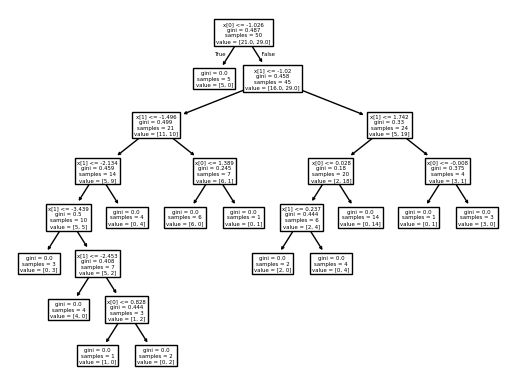

In [14]:
from sklearn.tree import plot_tree
     

plot_tree(clf1)

[Text(0.37037037037037035, 0.9583333333333334, 'x[1] <= -0.724\ngini = 0.493\nsamples = 50\nvalue = [28.0, 22.0]'),
 Text(0.2222222222222222, 0.875, 'x[1] <= -1.367\ngini = 0.375\nsamples = 8\nvalue = [2, 6]'),
 Text(0.2962962962962963, 0.9166666666666667, 'True  '),
 Text(0.14814814814814814, 0.7916666666666666, 'x[0] <= 0.312\ngini = 0.444\nsamples = 3\nvalue = [2, 1]'),
 Text(0.07407407407407407, 0.7083333333333334, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.2222222222222222, 0.7083333333333334, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.2962962962962963, 0.7916666666666666, 'gini = 0.0\nsamples = 5\nvalue = [0, 5]'),
 Text(0.5185185185185185, 0.875, 'x[1] <= 0.258\ngini = 0.472\nsamples = 42\nvalue = [26, 16]'),
 Text(0.4444444444444444, 0.9166666666666667, '  False'),
 Text(0.4444444444444444, 0.7916666666666666, 'gini = 0.0\nsamples = 8\nvalue = [8, 0]'),
 Text(0.5925925925925926, 0.7916666666666666, 'x[1] <= 0.498\ngini = 0.498\nsamples = 34\nvalue = [18, 16]')

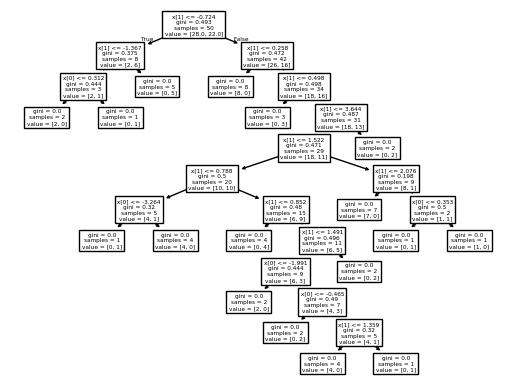

In [15]:
plot_tree(clf2)

[Text(0.23076923076923078, 0.9615384615384616, 'x[0] <= -2.436\ngini = 0.493\nsamples = 50\nvalue = [22.0, 28.0]'),
 Text(0.15384615384615385, 0.8846153846153846, 'gini = 0.0\nsamples = 5\nvalue = [5, 0]'),
 Text(0.19230769230769232, 0.9230769230769231, 'True  '),
 Text(0.3076923076923077, 0.8846153846153846, 'x[0] <= -0.777\ngini = 0.47\nsamples = 45\nvalue = [17, 28]'),
 Text(0.2692307692307693, 0.9230769230769231, '  False'),
 Text(0.15384615384615385, 0.8076923076923077, 'x[1] <= -2.606\ngini = 0.305\nsamples = 16\nvalue = [3, 13]'),
 Text(0.07692307692307693, 0.7307692307692307, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.23076923076923078, 0.7307692307692307, 'x[1] <= -0.853\ngini = 0.231\nsamples = 15\nvalue = [2, 13]'),
 Text(0.15384615384615385, 0.6538461538461539, 'gini = 0.0\nsamples = 8\nvalue = [0, 8]'),
 Text(0.3076923076923077, 0.6538461538461539, 'x[1] <= -0.406\ngini = 0.408\nsamples = 7\nvalue = [2, 5]'),
 Text(0.23076923076923078, 0.5769230769230769, 'gini = 

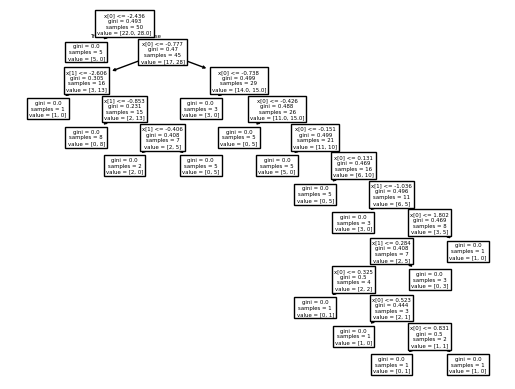

In [16]:

plot_tree(clf3)

In [17]:
clf1.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

/opt/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [18]:
clf2.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

/opt/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [19]:
clf3.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

/opt/anaconda3/envs/ml/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [20]:
df.sample(14,replace=True)

,col1,col2,col3,col4,col5,target
24,-1.324305,-0.360945,-2.487625,-0.649421,-0.557394,0
62,-3.920426,0.809085,-1.396589,1.774857,-1.564577,1
97,-0.608105,1.684293,3.041289,1.269194,0.043548,1
16,-2.646319,1.469123,0.202304,-4.052705,-1.563350,0
50,-0.226667,-0.462934,-2.755206,-0.013337,0.064741,0
71,1.041022,-0.513652,-3.426882,-0.103238,0.057516,0
85,-2.417353,0.627301,-0.088224,-0.218865,-0.216344,0
45,-2.640624,0.298874,0.172551,1.721129,-1.202745,1
44,-4.126667,-0.241792,-0.565350,-4.517919,-0.172330,0
77,1.115406,0.217695,-2.877635,0.680160,-0.753542,0
